# SARS-CoV-2: deer and mink against humans of the same lineage

---

### Why this notebook

Notebook 01 found deer genomes richer in C>T mutations than a baseline (the Nextclade reference tree), but flagged that the baseline mixes many lineages and could not rule out "deer just happened to carry lineages that are naturally C>T-heavy." This notebook removes that confound: for each animal lineage, it pulls **human genomes of the same lineage, the same country, and roughly the same period**, so lineage and geography are held fixed and only the host differs.

| Pair | Animal genomes | Human genomes |
|---|---|---|
| Deer, AY.103, USA | 55 | 502 |
| Deer, B.1.1.7, USA | 45 | 68 |
| Deer, B.1.2, USA | 40 | 501 |
| Mink, B.1.1.298, Denmark | 320 | 622 |
| Mink, B.1.8, Netherlands | 290 | 96 |
| Mink, B.1, USA | 215 | 494 |

Human genomes were pulled from GISAID hCoV-19 with Host = Human, the matching Lineage, Location and a Collection-date window covering the animal genomes' span, then subsampled to 500 per search (spread across months) with "Input for the Augur pipeline".

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

os.chdir(os.path.abspath("../.."))
pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
COL = {"deer": "#1B9E77", "mink": "#6A3D9A", "human": "#999999"}


## 1. Composition: no clean signal, same lesson as before

Mann-Whitney p-values against GC and CpG/UpA/TpC O/E, within each matched pair.

In [2]:
comp = pd.read_csv("results/sars2_within_lineage_composition.tsv", sep="\t")
mw = pd.read_csv("results/sars2_within_lineage_mw.tsv", sep="\t")
t = comp.merge(mw, on=["pair", "feature", "n_animal", "n_human"], how="left")
t["diff"] = (t.mean_animal - t.mean_human).round(5)
t[t.feature.isin(["gc_content", "oe_CG"])][["pair", "feature", "n_animal", "n_human", "mean_animal", "mean_human", "diff", "p"]].round(5)

,pair,feature,n_animal,n_human,mean_animal,mean_human,diff,p
0,"deer vs human, AY.103, USA",gc_content,55,502,0.37917,0.37951,-0.00034,0.00000
1,"deer vs human, AY.103, USA",oe_CG,55,502,0.40780,0.40808,-0.00028,0.01761
4,"deer vs human, B.1.1.7, USA",gc_content,45,68,0.37875,0.37963,-0.00089,0.00000
5,"deer vs human, B.1.1.7, USA",oe_CG,45,68,0.40671,0.40707,-0.00036,0.21916
8,"deer vs human, B.1.2, USA",gc_content,40,501,0.37952,0.37962,-0.00010,0.00006
9,"deer vs human, B.1.2, USA",oe_CG,40,501,0.40639,0.40658,-0.00018,0.08773
12,"mink vs human, B.1.1.298, Denmark",gc_content,320,622,0.37991,0.37990,0.00000,0.61355
13,"mink vs human, B.1.1.298, Denmark",oe_CG,320,622,0.40833,0.40818,0.00015,0.04949
16,"mink vs human, B.1.8, Netherlands",gc_content,290,96,0.37981,0.38002,-0.00020,0.00000
17,"mink vs human, B.1.8, Netherlands",oe_CG,290,96,0.40629,0.40721,-0.00091,0.00000


**Reading it.** Several GC comparisons hit p < 0.0001 (large n makes tiny differences significant, the same p-value-inflation problem as RSV), but the **actual differences are in the fourth decimal** (0.3787 vs 0.3796, a gap of 0.0009). CpG O/E differences are similarly small. **Composition still carries no usable signal** once you look at the size of the gap rather than the p-value.

## 2. The recent-mutation spectrum, within matched lineage

Same filters as before: genomes with at most 1% ambiguous bases and at most 30 recent (private) mutations. The share that is C>T, with a genome-resampled 95% interval (genomes in a pair share some ancestry, so the true interval is likely wider than this).

In [3]:
ci = pd.read_csv("results/sars2_within_lineage_ct_ci.tsv", sep="\t")
ci[["pair", "n_animal", "animal_C>T", "animal_ci_lo", "animal_ci_hi", "n_human", "human_C>T", "human_ci_lo", "human_ci_hi"]].round(3)

,pair,n_animal,animal_C>T,animal_ci_lo,animal_ci_hi,n_human,human_C>T,human_ci_lo,human_ci_hi
0,"deer, AY.103, USA",51,0.637,0.597,0.677,502,0.401,0.385,0.418
1,"deer, B.1.1.7, USA",11,0.761,0.709,0.802,62,0.525,0.462,0.587
2,"deer, B.1.2, USA",40,0.644,0.604,0.677,501,0.401,0.384,0.417
3,"mink, B.1.1.298, Denmark",319,0.626,0.603,0.649,622,0.604,0.585,0.624
4,"mink, B.1.8, Netherlands",290,0.458,0.451,0.465,96,0.392,0.351,0.430
5,"mink, B.1, USA",215,0.416,0.405,0.426,490,0.442,0.423,0.462


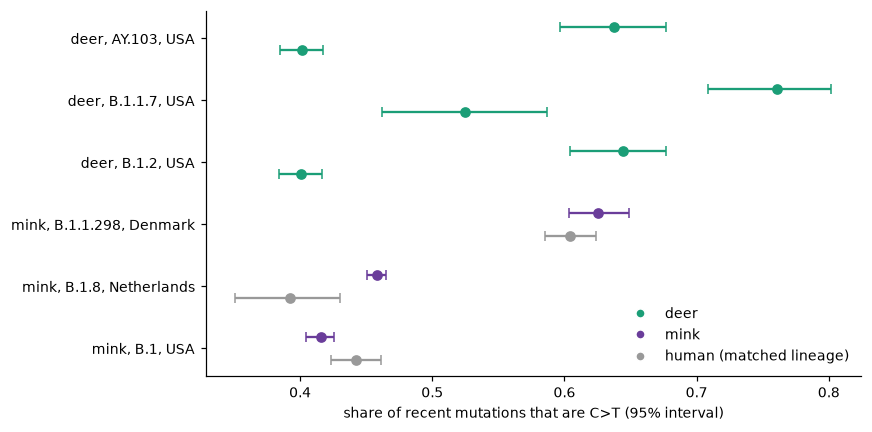

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(ci))
for off, who, c in ((-.18, "animal", None), (.18, "human", COL["human"])):
    for i, r in ci.iterrows():
        col = COL["deer"] if r.pair.startswith("deer") else COL["mink"] if who == "animal" else COL["human"]
        lo, hi, m = (r.animal_ci_lo, r.animal_ci_hi, r["animal_C>T"]) if who == "animal" else (r.human_ci_lo, r.human_ci_hi, r["human_C>T"])
        ax.errorbar(m, i + off, xerr=[[m - lo], [hi - m]], fmt="o", color=col, capsize=3,
                   label=who if i == 0 else None)
ax.set_yticks(y); ax.set_yticklabels(ci.pair); ax.invert_yaxis()
ax.set_xlabel("share of recent mutations that are C>T (95% interval)")
from matplotlib.lines import Line2D
handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=COL["deer"], label="deer"),
          Line2D([0], [0], marker="o", color="w", markerfacecolor=COL["mink"], label="mink"),
          Line2D([0], [0], marker="o", color="w", markerfacecolor=COL["human"], label="human (matched lineage)")]
ax.legend(handles=handles, frameon=False, loc="lower right")
plt.tight_layout(); fig.savefig("results/figures/sars2_within_lineage_ct.png", dpi=200, bbox_inches="tight"); plt.show()

**Reading it.**

- **Deer: higher than human in all three lineages, and every interval is clear of the human one.** AY.103: 0.64 (deer) vs 0.40 (human); B.1.1.7: 0.76 vs 0.53; B.1.2: 0.64 vs 0.40. Three independent lineages, three different outbreaks, the same direction and a similar gap (about 1.5-2x). **This is no longer explainable by "deer happened to carry C>T-heavy lineages"** — within each lineage, deer genomes of that lineage are still more C>T-rich than human genomes of that same lineage.
- **Mink: no consistent direction.** B.1.1.298 overlaps (0.60 vs 0.63, both close); B.1.8 mink is higher (0.46 vs 0.39, barely non-overlapping); B.1 mink is if anything slightly *lower* than human (0.42 vs 0.44). Mink does not repeat the deer pattern.

## 3. What this means

| Question | Answer |
|---|---|
| Is the deer C>T excess a lineage-sampling artefact? | **No.** It holds within three separate matched lineages. |
| Is it a host effect specific to deer, or general to all SARS-CoV-2 animal hosts? | **Specific to deer**, as far as this data shows — mink does not share it. |
| Composition? | Still nothing, confirmed again with matched comparisons. |

This is the project's cleanest positive SARS-CoV-2 result: **a consistent, lineage-independent, host-linked mutation-spectrum signature in deer**, found by comparing matched human and deer genomes of the same lineage rather than relying on a mixed baseline.

### Limits

- **Not proven mechanistic.** A C>T excess is consistent with APOBEC-type editing (as in mpox) or another deer-specific mutational process, but this data does not identify the enzyme or the sequence context.
- **Small animal n for B.1.1.7** (11 good-quality deer genomes): the direction is clear but the estimate is the least precise of the three.
- **Bootstrap intervals resample genomes, not independent lineages or farms**, so they likely understate the true uncertainty, same caveat as the mpox analysis.
- **Geography is matched by country, not down to state/region**; some residual geographic confounding with lineage sub-structure is possible.

### Next steps

1. **Sequence context test** (as in the mpox analysis): is the deer C>T excess concentrated at a particular dinucleotide context (e.g. preceded by T, as APOBEC3 would predict), or spread evenly? That would distinguish a known host-enzyme mechanism from an unexplained one.
2. **Within-lineage test for cats**, if enough matched human genomes of the cats' lineages can be pulled — cats currently only have the mixed-baseline comparison.
3. **Report to the mentor**: three independent lineages agreeing, with a human comparison matched on lineage/country/era, is a defensible host-transmission finding worth writing up formally.